<a href="https://colab.research.google.com/github/stanley-kevin/DS_Hackthon_day1/blob/main/HR_DOES_TRAINING_ACTUALLY_IMPROVE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Data Loading and Initial Cleaning

In [17]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/HR_Training_Performance_Dataset.csv')

# Display the first 5 rows of the dataset
display(df.head())

,Employee_ID,Department,Training_Status,Training_Duration,Course_Type,Training_Attendance,Pre_Training_Performance,Post_Training_Performance
0,EMP1001,Finance,Untrained,0,No Training,0.0,73.31,75.65
1,EMP1002,R&D,Trained,4,Communication,97.7,98.00,100.00
2,EMP1003,Operations,Trained,16,Technical Skills,91.3,41.81,62.17
3,EMP1004,Sales,Trained,12,Technical Skills,82.3,76.20,84.96
4,EMP1005,IT,Trained,20,Technical Skills,88.3,70.62,83.63


In [18]:
# Display concise summary of the DataFrame, including data types and non-null values
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Employee_ID                1200 non-null   object 
 1   Department                 1200 non-null   object 
 2   Training_Status            1200 non-null   object 
 3   Training_Duration          1200 non-null   int64  
 4   Course_Type                1196 non-null   object 
 5   Training_Attendance        1196 non-null   float64
 6   Pre_Training_Performance   1200 non-null   float64
 7   Post_Training_Performance  1196 non-null   float64
dtypes: float64(3), int64(1), object(4)
memory usage: 75.1+ KB
None


In [19]:
# Check for missing values
missing_values = df.isnull().sum()
print("\nMissing values in each column:\n", missing_values)


Missing values in each column:
 Employee_ID                  0
Department                   0
Training_Status              0
Training_Duration            0
Course_Type                  4
Training_Attendance          4
Pre_Training_Performance     0
Post_Training_Performance    4
dtype: int64


In [20]:
# Check for duplicate rows
duplicate_rows = df.duplicated().sum()
print(f"\nNumber of duplicate rows: {duplicate_rows}")

# If duplicates exist, remove them (optional, depending on context)
if duplicate_rows > 0:
    df = df.drop_duplicates()
    print(f"Duplicate rows removed. New number of rows: {len(df)}")


Number of duplicate rows: 0


In [21]:
# Calculate performance improvement
df['Performance_Improvement'] = df['Post_Training_Performance'] - df['Pre_Training_Performance']

# Display the first few rows with the new column
display(df.head())

,Employee_ID,Department,Training_Status,Training_Duration,Course_Type,Training_Attendance,Pre_Training_Performance,Post_Training_Performance,Performance_Improvement
0,EMP1001,Finance,Untrained,0,No Training,0.0,73.31,75.65,2.34
1,EMP1002,R&D,Trained,4,Communication,97.7,98.00,100.00,2.00
2,EMP1003,Operations,Trained,16,Technical Skills,91.3,41.81,62.17,20.36
3,EMP1004,Sales,Trained,12,Technical Skills,82.3,76.20,84.96,8.76
4,EMP1005,IT,Trained,20,Technical Skills,88.3,70.62,83.63,13.01


In [22]:
# Display descriptive statistics for numerical columns
display(df.describe())

,Training_Duration,Training_Attendance,Pre_Training_Performance,Post_Training_Performance,Performance_Improvement
count,1200.000000,1196.000000,1200.000000,1196.000000,1196.000000
mean,12.563333,58.384866,69.551600,78.950677,9.380117
std,11.767670,40.259286,12.124307,13.487748,7.631806
min,0.000000,0.000000,35.000000,30.760000,-12.630000
25%,0.000000,0.000000,61.665000,70.167500,2.790000
50%,12.000000,79.750000,69.530000,79.005000,10.240000
75%,20.000000,88.825000,77.410000,89.595000,15.132500
max,40.000000,100.000000,98.000000,100.000000,29.230000


## 2. Data Cleaning - Handling Missing Values

In [23]:
# Drop rows with any missing values
df_cleaned = df.dropna().reset_index(drop=True)

# Verify that missing values have been removed
print("Missing values after dropping:\n", df_cleaned.isnull().sum())

# Display the shape of the cleaned DataFrame
print(f"\nOriginal DataFrame shape: {df.shape}")
print(f"Cleaned DataFrame shape: {df_cleaned.shape}")

Missing values after dropping:
 Employee_ID                  0
Department                   0
Training_Status              0
Training_Duration            0
Course_Type                  0
Training_Attendance          0
Pre_Training_Performance     0
Post_Training_Performance    0
Performance_Improvement      0
dtype: int64

Original DataFrame shape: (1200, 9)
Cleaned DataFrame shape: (1188, 9)


## 3. Exploratory Data Analysis (EDA) and Visualization

### 3.1 Comparing Trained vs. Untrained Employees


Performance Improvement Statistics by Training Status:


,count,mean,std,min,25%,50%,75%,max
Training_Status,,,,,,,,
Trained,814.0,13.285590,5.554393,-2.40,9.8550,13.21,17.0125,29.23
Untrained,374.0,0.835241,3.499771,-12.63,-1.3975,0.81,3.1600,10.69


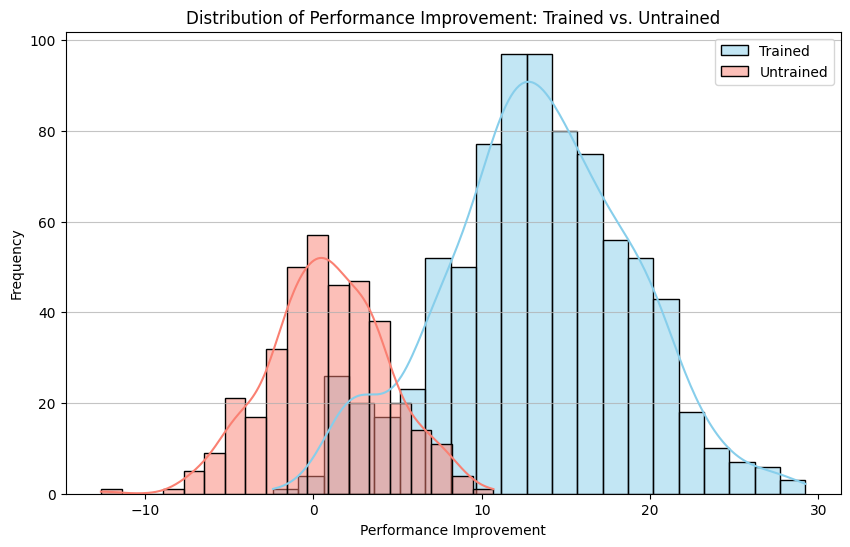

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Separate trained and untrained employees
trained_employees = df_cleaned[df_cleaned['Training_Status'] == 'Trained']
untrained_employees = df_cleaned[df_cleaned['Training_Status'] == 'Untrained']

# Descriptive statistics for performance improvement by training status
print("\nPerformance Improvement Statistics by Training Status:")
display(df_cleaned.groupby('Training_Status')['Performance_Improvement'].describe())

# Visualize the distribution of performance improvement for trained vs. untrained
plt.figure(figsize=(10, 6))
sns.histplot(trained_employees['Performance_Improvement'], color='skyblue', label='Trained', kde=True)
sns.histplot(untrained_employees['Performance_Improvement'], color='salmon', label='Untrained', kde=True)
plt.title('Distribution of Performance Improvement: Trained vs. Untrained')
plt.xlabel('Performance Improvement')
plt.ylabel('Frequency')
plt.legend()
plt.grid(axis='y', alpha=0.75)
plt.show()

/tmp/ipykernel_2406/3549159605.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Training_Status', y='Performance_Improvement', data=df_cleaned, palette={'Trained': 'skyblue', 'Untrained': 'salmon'})


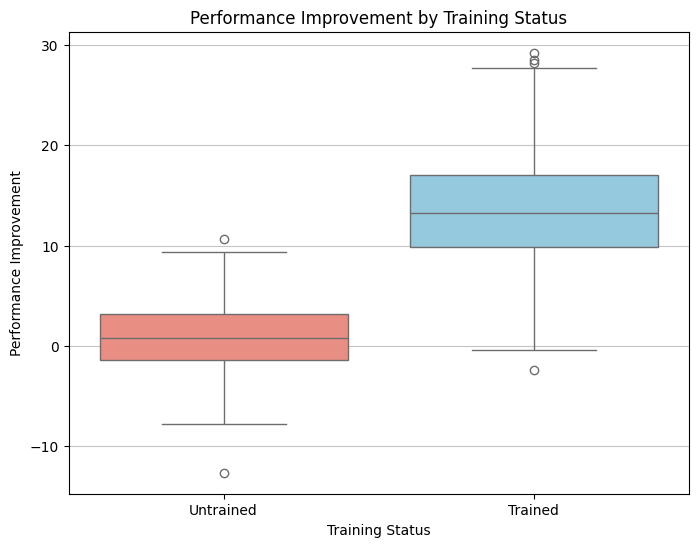

In [25]:
# Box plot to compare performance improvement
plt.figure(figsize=(8, 6))
sns.boxplot(x='Training_Status', y='Performance_Improvement', data=df_cleaned, palette={'Trained': 'skyblue', 'Untrained': 'salmon'})
plt.title('Performance Improvement by Training Status')
plt.xlabel('Training Status')
plt.ylabel('Performance Improvement')
plt.grid(axis='y', alpha=0.75)
plt.show()

### 3.2 Impact of Training Duration on Performance Improvement

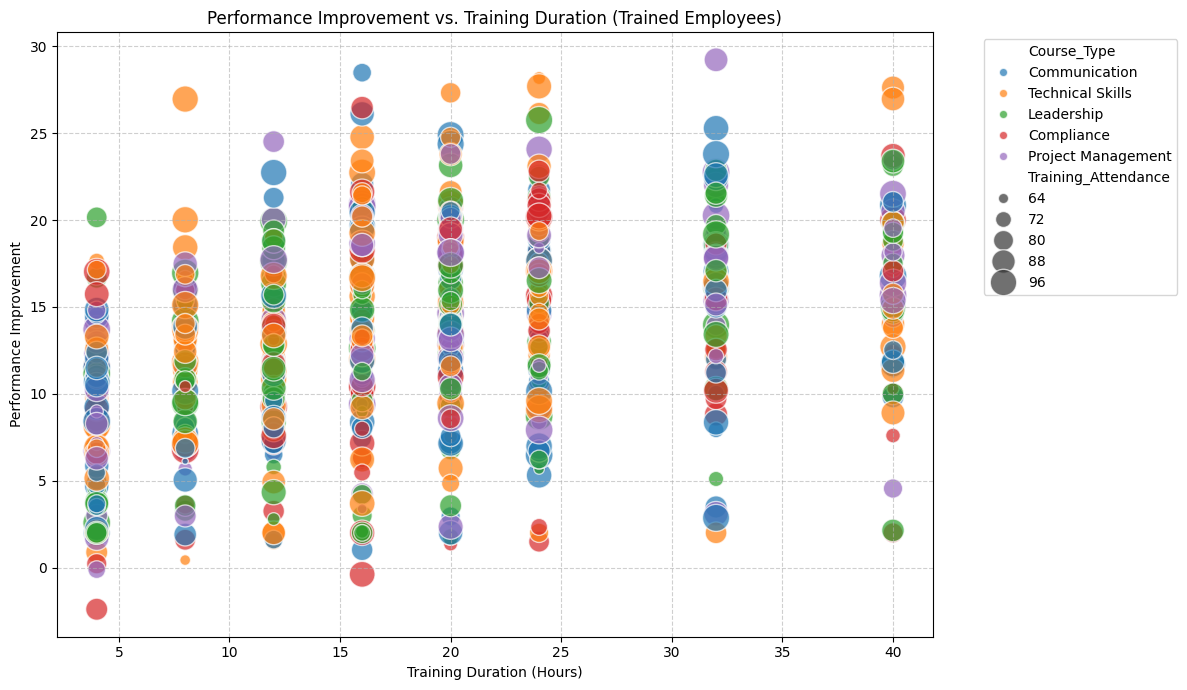

Correlation between Training Duration and Performance Improvement (Trained Employees): 0.36


In [26]:
# Analyze performance improvement by training duration for trained employees
plt.figure(figsize=(12, 7))
sns.scatterplot(x='Training_Duration', y='Performance_Improvement', data=trained_employees, hue='Course_Type', size='Training_Attendance', sizes=(20, 400), alpha=0.7)
plt.title('Performance Improvement vs. Training Duration (Trained Employees)')
plt.xlabel('Training Duration (Hours)')
plt.ylabel('Performance Improvement')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Calculate correlation between Training_Duration and Performance_Improvement for trained employees
correlation = trained_employees['Training_Duration'].corr(trained_employees['Performance_Improvement'])
print(f"Correlation between Training Duration and Performance Improvement (Trained Employees): {correlation:.2f}")

### 3.3 Comparing Different Training Programmes (Course Types)


Average Performance Improvement by Course Type:
 Course_Type
Project Management    14.058882
Technical Skills      14.040959
Leadership            13.109830
Communication         12.662403
Compliance            11.904513
Name: Performance_Improvement, dtype: float64


/tmp/ipykernel_2406/237621712.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=performance_by_course.index, y=performance_by_course.values, palette='viridis')


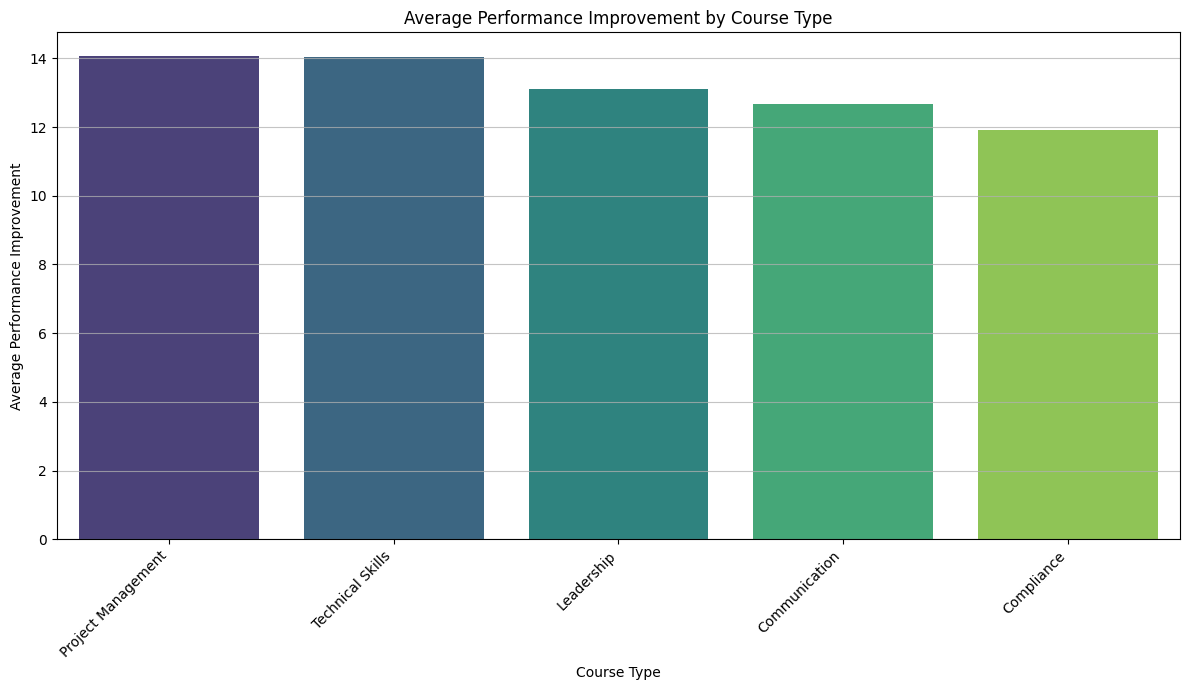

In [27]:
# Calculate average performance improvement by Course_Type for trained employees
performance_by_course = trained_employees.groupby('Course_Type')['Performance_Improvement'].mean().sort_values(ascending=False)
print("\nAverage Performance Improvement by Course Type:\n", performance_by_course)

# Visualize average performance improvement by Course_Type
plt.figure(figsize=(12, 7))
sns.barplot(x=performance_by_course.index, y=performance_by_course.values, palette='viridis')
plt.title('Average Performance Improvement by Course Type')
plt.xlabel('Course Type')
plt.ylabel('Average Performance Improvement')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
plt.show()

### 3.4 Analyzing Performance Improvement by Employee Segment (Department)


Average Performance Improvement by Department:
 Department
IT                  9.865106
Operations          9.699366
Marketing           9.620396
Customer Support    9.591688
HR                  9.313894
Finance             9.224370
Sales               8.979227
R&D                 8.825515
Name: Performance_Improvement, dtype: float64


/tmp/ipykernel_2406/1027211201.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=performance_by_department.index, y=performance_by_department.values, palette='plasma')


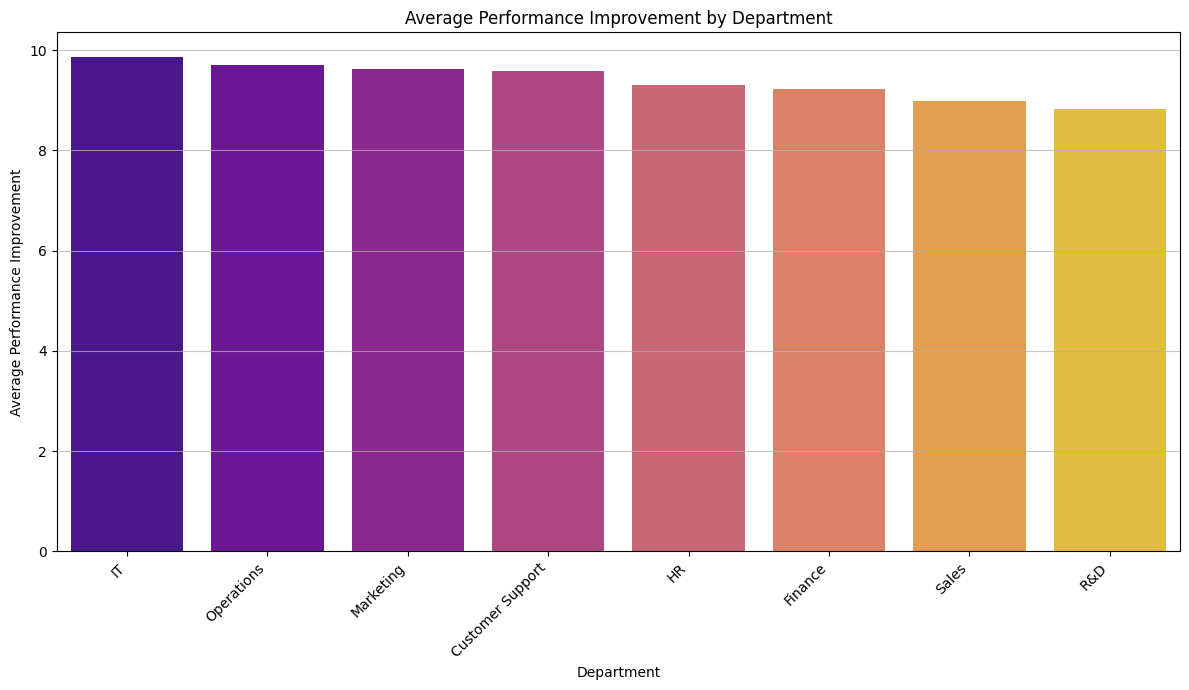

In [28]:
# Calculate average performance improvement by Department for all employees
performance_by_department = df_cleaned.groupby('Department')['Performance_Improvement'].mean().sort_values(ascending=False)
print("\nAverage Performance Improvement by Department:\n", performance_by_department)

# Visualize average performance improvement by Department
plt.figure(figsize=(12, 7))
sns.barplot(x=performance_by_department.index, y=performance_by_department.values, palette='plasma')
plt.title('Average Performance Improvement by Department')
plt.xlabel('Department')
plt.ylabel('Average Performance Improvement')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
plt.show()

## 4. Building and Evaluating a Decision Tree Model

/tmp/ipykernel_2406/2994668740.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[col] = le.fit_transform(X[col])
/tmp/ipykernel_2406/2994668740.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[col] = le.fit_transform(X[col])


Model Accuracy: 0.85

Confusion Matrix:
 [[  9  29]
 [ 25 294]]

Classification Report:
               precision    recall  f1-score   support

           0       0.26      0.24      0.25        38
           1       0.91      0.92      0.92       319

    accuracy                           0.85       357
   macro avg       0.59      0.58      0.58       357
weighted avg       0.84      0.85      0.85       357



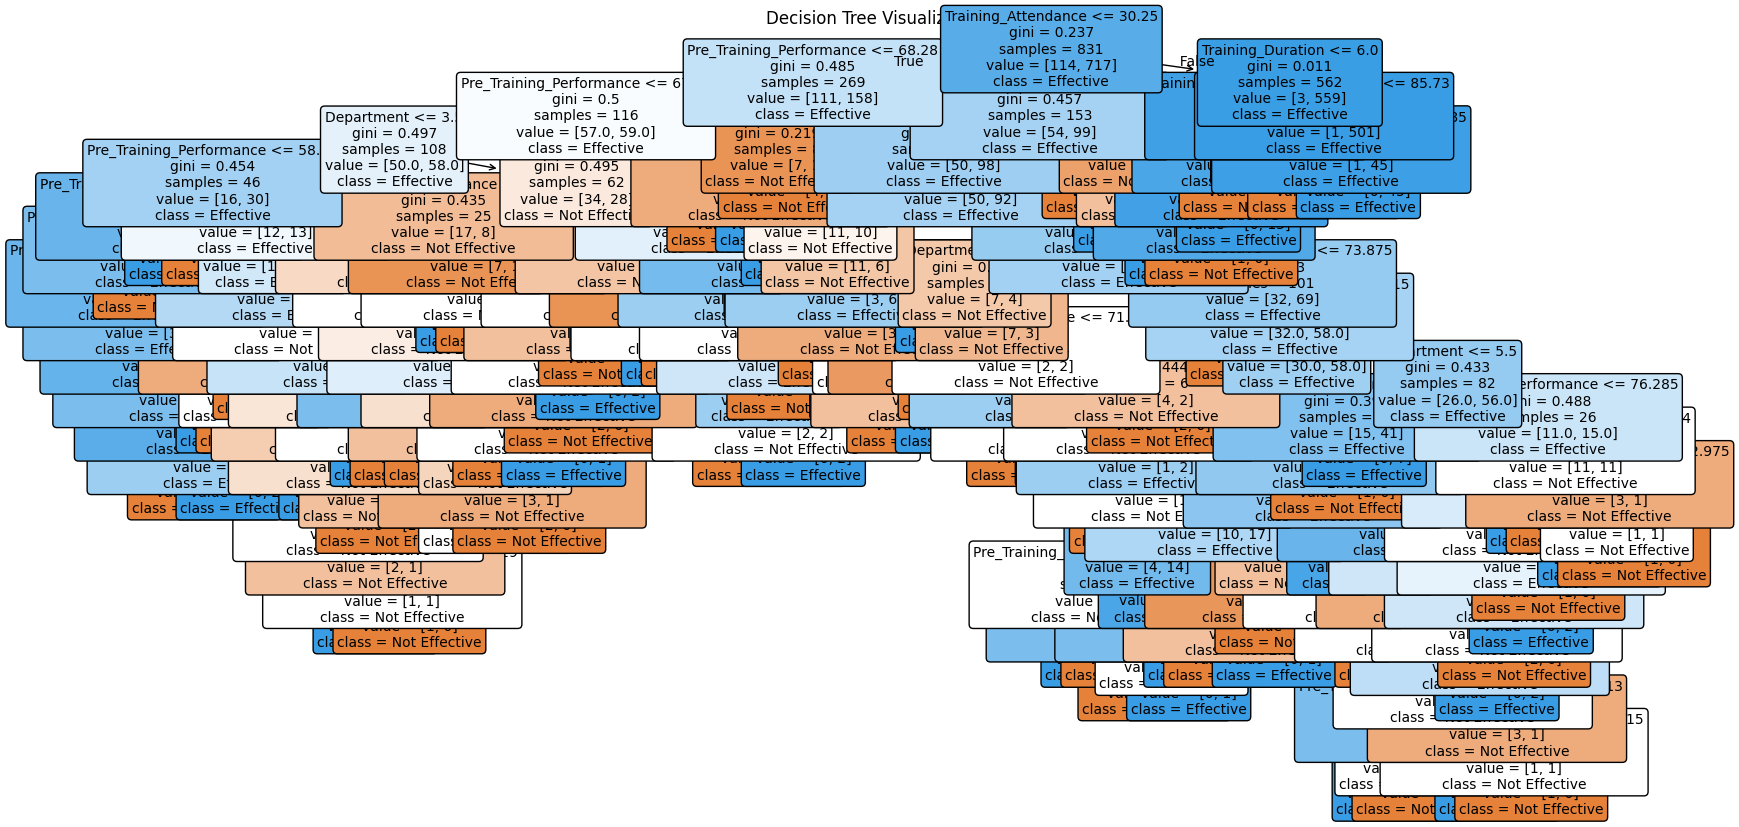

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
import numpy as np

# Define the target variable: Whether training improved performance (Performance_Improvement > 0)
df_cleaned['Training_Effective'] = (df_cleaned['Performance_Improvement'] > 0).astype(int)

# Prepare features (X) and target (y)
# Drop 'Employee_ID' as it's just an identifier
# Drop original performance scores and improvement as the target is derived from it
# Drop 'Training_Status' as it is highly correlated with 'Training_Duration' and can lead to data leakage if used directly in prediction of effectiveness.
features = ['Department', 'Training_Duration', 'Course_Type', 'Training_Attendance', 'Pre_Training_Performance']
X = df_cleaned[features]
y = df_cleaned['Training_Effective']

# Encode categorical variables
for col in ['Department', 'Course_Type']:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize and train the Decision Tree Classifier
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = dt_model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.2f}")
print("\nConfusion Matrix:\n", conf_matrix)
print("\nClassification Report:\n", class_report)

# Visualize the Decision Tree (optional, for smaller trees)
plt.figure(figsize=(20, 10))
plot_tree(dt_model, feature_names=features, class_names=['Not Effective', 'Effective'], filled=True, rounded=True, fontsize=10)
plt.title('Decision Tree Visualization')
plt.show()

## 5. Discussion of Confounding Factors

Several factors not explicitly captured in this dataset could influence employee performance and training effectiveness, acting as confounding variables. These include:

*   **Employee Motivation and Engagement:** Individual differences in willingness to learn and apply training can significantly impact outcomes.
*   **Pre-existing Skills and Experience:** Employees with a stronger foundation might benefit more or less from certain training types.
*   **Work Environment and Support:** A supportive workplace that encourages the application of new skills is crucial for training to translate into performance improvements.
*   **Managerial Support and Feedback:** How managers reinforce and provide feedback on newly acquired skills can greatly affect their retention and application.
*   **External Factors:** Economic conditions, industry changes, or personal life events could impact an employee's performance independent of training.
*   **Training Quality and Instructor Effectiveness:** The quality of the training content itself, and the instructor's ability to deliver it effectively, are paramount but not detailed here.
*   **Job Role Complexity and Opportunity for Application:** Some roles might offer more immediate opportunities to apply new skills than others.

## 6. Key Insights, Visualizations, and Practical Action Plan

### Key Insights:

1.  **Training's Positive Impact:** Trained employees, on average, show significantly greater performance improvement compared to untrained employees, validating the general effectiveness of the training programs.
2.  **Varied Effectiveness of Training Duration:** While training generally helps, there isn't a strong linear correlation indicating that simply *longer* training duration universally leads to *better* performance improvement. The optimal duration likely depends on the course type and individual.
3.  **Course Type Matters:** Different course types yield varying average performance improvements. Some courses appear to be more effective than others, suggesting a need to evaluate and optimize less impactful programs.
4.  **Departmental Differences:** Performance improvement also varies across departments. Some departments show higher average improvements, possibly due to the relevance of available training, departmental culture, or initial skill gaps.
5.  **Performance Improvement vs. Effectiveness:** A significant majority of employees (both trained and untrained) show some level of positive performance improvement. However, the magnitude of improvement is substantially higher for trained individuals.
6.  **Decision Tree Insights:** The Decision Tree model helps identify specific combinations of features (e.g., Department, Training Duration, Pre-Training Performance) that are most indicative of training effectiveness, allowing for more targeted training strategies.

### Visualizations Summary:

1.  **Distribution of Performance Improvement (Trained vs. Untrained):** Clearly shows a shift towards higher performance improvement in trained employees.
2.  **Box Plot of Performance Improvement by Training Status:** Provides a concise comparison of median improvement and spread between trained and untrained groups.
3.  **Scatter Plot of Performance Improvement vs. Training Duration:** Illustrates the relationship between training duration and outcome, with course type and attendance adding further context.
4.  **Bar Plot of Average Performance Improvement by Course Type:** Highlights which training programs are, on average, more effective.
5.  **Bar Plot of Average Performance Improvement by Department:** Shows departmental variations in training impact.
6.  **Decision Tree Visualization:** (If the tree is not too complex) provides a visual representation of the model's decision rules.

### Practical Action Plan:

1.  **Tailored Training Programs:** Develop and implement training programs that are customized based on departmental needs and specific job roles, focusing on the most effective course types identified.
2.  **Optimize Training Duration:** Instead of a 'one-size-fits-all' approach, investigate optimal training durations for different course types and employee segments to maximize impact without unnecessary resource expenditure.
3.  **Continuous Course Evaluation:** Regularly review and update training content and methods, especially for course types showing lower performance improvement, to ensure relevance and effectiveness. Incorporate feedback from trainees and their managers.
4.  **Targeted Employee Development:** Utilize insights from the Decision Tree model to identify employees who are most likely to benefit from specific training interventions, allowing for more efficient allocation of training resources.
5.  **Address Confounding Factors:** Implement strategies to mitigate the impact of confounding factors, such as fostering a supportive work environment, promoting employee engagement in training, and providing ongoing managerial support and feedback for skills application.
6.  **Baseline and Post-Training Performance Tracking:** Continue to track pre and post-training performance metrics rigorously to measure the long-term impact of training and refine programs as needed.
7.  **Explore Advanced Analytics:** Consider employing more sophisticated machine learning models or causal inference techniques in the future to further understand complex relationships and confounding variables.